In [1]:
"""
check if the noise is correlated on either side of a streak

let's also check how well the method of deciding what streaks to include works
"""

'\ncheck if the noise is correlated on either side of a streak\n'

In [39]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
# import scipy.ndimage as snm


import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
# import implantation_functions as imp
# from tensorflow import keras
import get_postage_stamps as gpsf
import fitting

# from scipy.ndimage import sobel
# from scipy.signal import find_peaks
import importlib
import random
from pathlib import Path
import re


In [40]:
fnames = ['ztf_20221020148032_000686_zg_c05_x_0002.fits.fz',
          'ztf_20221020163819_000640_zg_c12_x_0001.fits.fz',
          'ztf_20221020297847_000449_zr_c04_x_0011.fits.fz',
          'ztf_20221020154120_000640_zi_c15_x_0028.fits.fz',
          'ztf_20221020294271_000449_zr_c16_x_0012.fits.fz',
          'ztf_20221020154120_000640_zi_c12_x_0028.fits.fz',
          'ztf_20221020138241_000686_zi_c16_x_0001.fits.fz',
          'ztf_20221020154120_000640_zi_c08_x_0014.fits.fz',
          'ztf_20221020148032_000686_zg_c16_x_0014.fits.fz',
           'ztf_20221020141806_000686_zi_c16_x_0020.fits.fz']
          
          
          
images = []        
path = '/lustre/lrspec/ZTF_data/2022/1020/'     
          
for fname in fnames:
    file = fits.open(path+fname)
    for i in range(1,5):
        image = file[i].data
        images.append(image)

In [41]:
from scipy.signal import find_peaks


In [42]:
def get_streak_locations(image):
    averages = np.average(image[35:-35,35:-35], axis=0) #cut off edges
    peaks, heights = find_peaks(averages, height=(None, None))
    min_height = np.sort(heights['peak_heights'])[-10]
    tall_map = heights['peak_heights']>=min_height
    tall_peaks = peaks[tall_map]+35
    return tall_peaks

In [43]:
def get_noise_left(image, streak_location):
    array_left = image[:,streak_location-20:streak_location-10]
    noise_left = np.average(array_left, axis=1)
    return(noise_left)

In [44]:
def get_noise_right(image, streak_location):
    array_right = image[:,streak_location+10:streak_location+20]
    noise_right = np.average(array_right, axis=1)
    return(noise_right)

In [20]:
%matplotlib inline

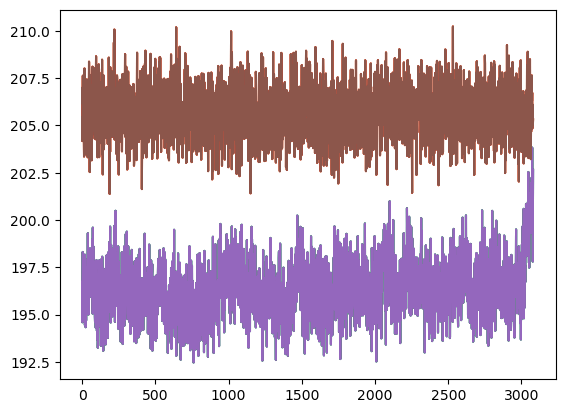

In [22]:
plt.plot(get_noise_right(image,616))
plt.plot(get_noise_left(image,616))
plt.show()

In [12]:
get_noise_left(image,616)

array([205.44461, 204.17581, 206.53447, ..., 205.30672, 205.0561 ,
       205.32144], dtype=float32)

In [23]:
np.dot(get_noise_right(image,616),get_noise_left(image,616).T)

124411330.0

In [27]:
r= np.corrcoef(get_noise_right(image,616),get_noise_left(image,616))[0, 1]
print(r)

[0.01721055 1.        ]


In [28]:
from scipy.stats import pearsonr
r, p = pearsonr(get_noise_right(image,616),get_noise_left(image,616))

In [29]:
r, p

(0.017210550735693265, 0.33966377309769186)

In [30]:
rs = []
ps = []
for image in images:
    locations = get_streak_locations(image)
    for location in locations:
        right = get_noise_right(image, location)
        left = get_noise_left(image, location)
        r, p = pearsonr(right, left)
        rs.append(r)
        ps.append(p)

In [38]:
np.min(rs)

-0.2243456461988519

In [35]:
np.average(rs), np.std(rs), np.average(ps), np.std(ps)

(0.004297724681813709,
 0.028193366041352218,
 0.3913540864208387,
 0.29343021013045717)

163.12804 165.81804
163.94757 163.84879
163.69788 162.63156
166.7884 169.52226
177.57944 169.46416
169.39304 167.96323
181.35754 171.26779
169.91234 191.68831
191.68263 171.40524
174.125 171.14745


Text(0.5, 1.0, 'streak fluxes from streaks in one image')

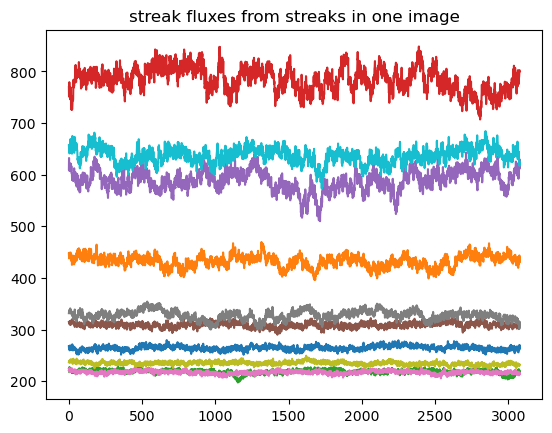

In [51]:

for image in images:
    locations = get_streak_locations(image)
    for location in locations:
        array = image[:,location-3:location+2]
        streak = np.average(array, axis=1)
        right = get_noise_right(image, location)
        left = get_noise_left(image, location)
        print(np.average(left), np.average(right))
        plt.plot(streak)
    break
plt.title("streak fluxes from streaks in one image")

184.60426 177.49236
189.0615 174.00868
193.44795 185.18849
188.4121 188.02696
182.00365 181.02306
181.27585 196.54028
241.54791 183.43332
193.2809 183.96844
178.36043 181.09573
211.96677 178.914


Text(0.5, 1.0, 'streak fluxes from streaks in one (different) image')

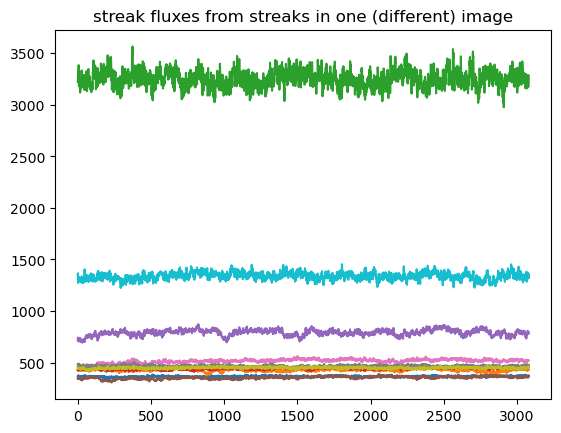

In [53]:
for image in images[2:]:
    locations = get_streak_locations(image)
    for location in locations:
        array = image[:,location-3:location+2]
        streak = np.average(array, axis=1)
        right = get_noise_right(image, location)
        left = get_noise_left(image, location)
        print(np.average(left), np.average(right))
        plt.plot(streak)
    break
plt.title("streak fluxes from streaks in one (different) image")

184.60426 177.49236


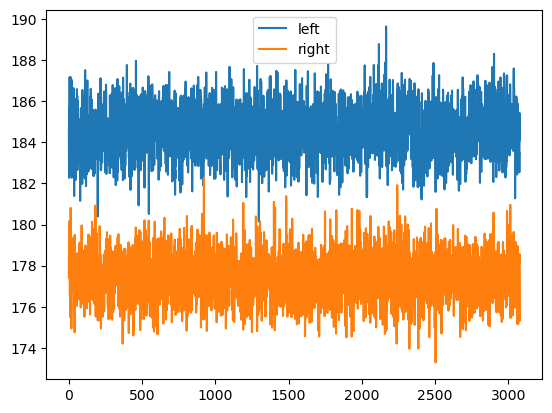

189.0615 174.00868


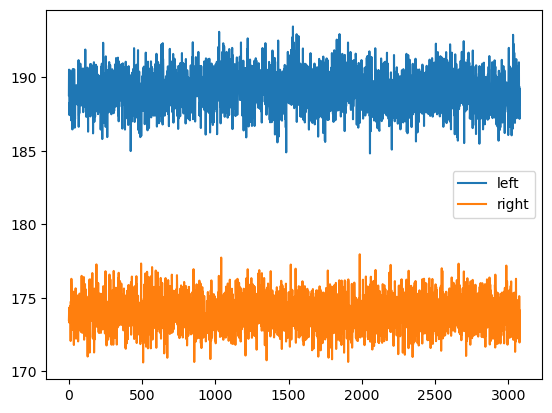

193.44795 185.18849


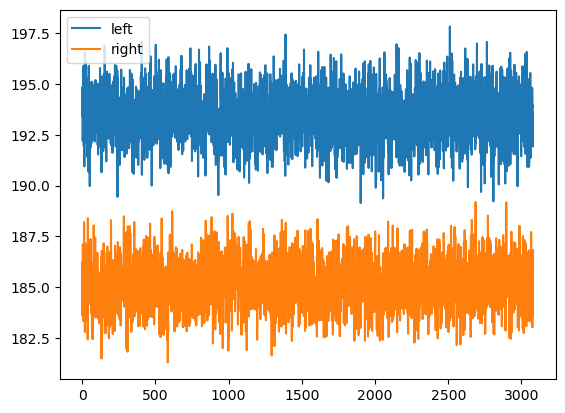

188.4121 188.02696


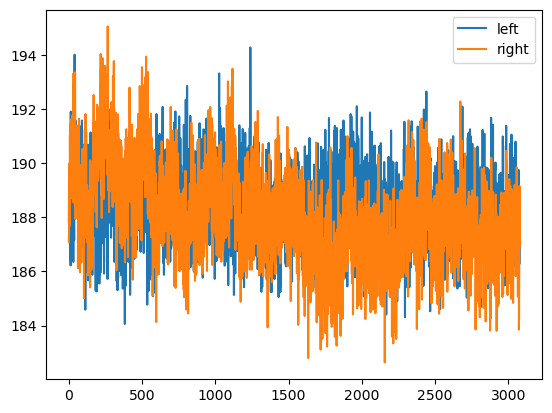

182.00365 181.02306


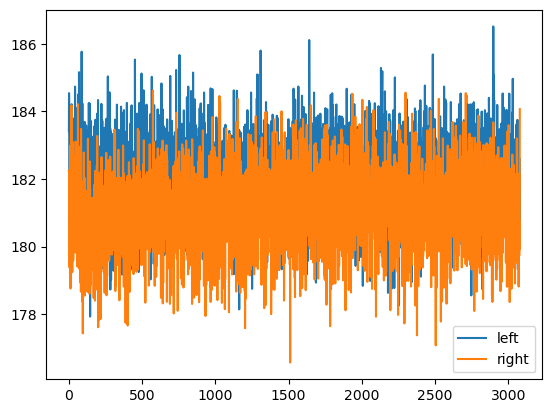

181.27585 196.54028


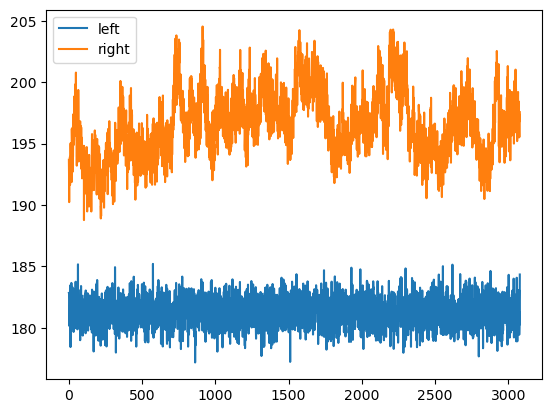

241.54791 183.43332


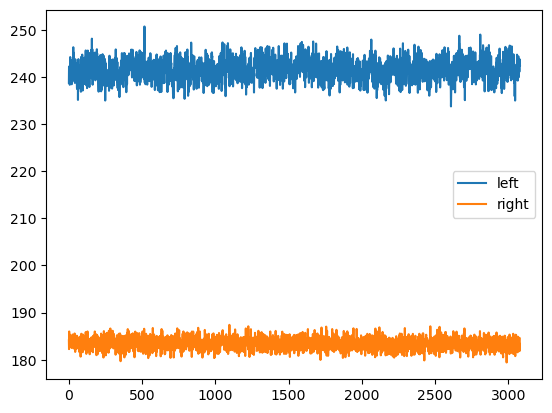

193.2809 183.96844


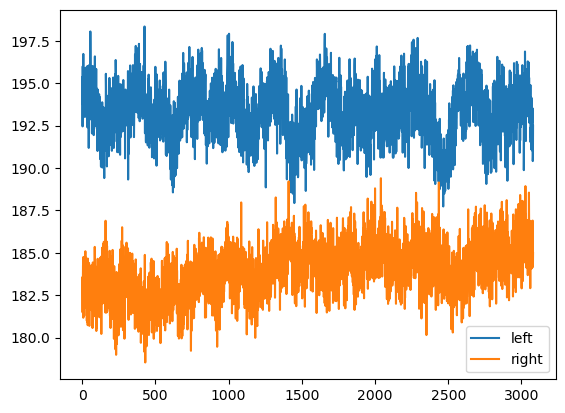

178.36043 181.09573


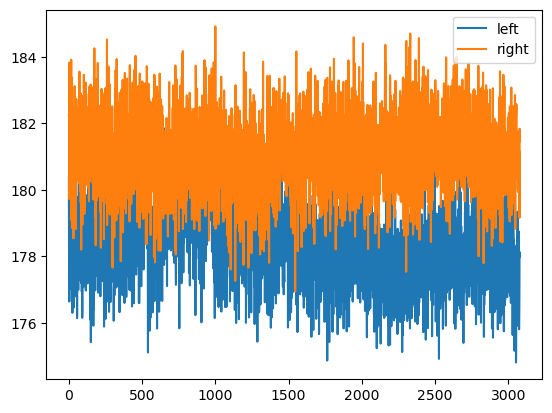

211.96677 178.914


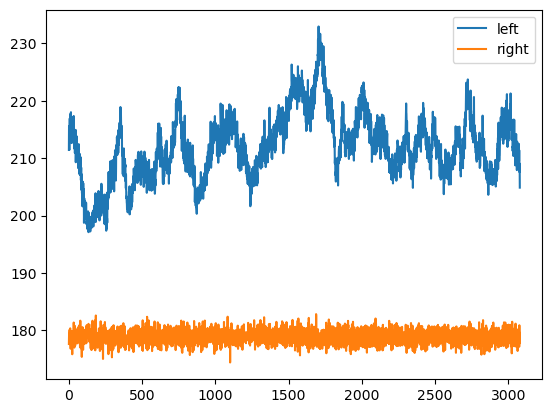

In [55]:
for image in images[2:]:
    locations = get_streak_locations(image)
    for location in locations:
        array = image[:,location-3:location+2]
        streak = np.average(array, axis=1)
        right = get_noise_right(image, location)
        left = get_noise_left(image, location)
        print(np.average(left), np.average(right))
        # plt.plot(streak, label='streak')
        plt.plot(left, label='left')
        plt.plot(right, label='right')
        plt.legend()
        plt.show()
    break
# plt.title("streak fluxes from streaks in one (different) image")

In [61]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit


def gaussian(x, amp, cen, sigma):
    return amp * np.exp(-((x - cen) ** 2) / (2 * sigma**2))


def get_streak_profile(image, center_value_y=1500, half_height=10):
    """Background-subtracted column profile, same as in implant_transient_full_image."""
    background = rff.get_image_background(image)
    nobg = image - np.full(np.shape(image), background)
    return np.average(
        nobg[center_value_y - half_height : center_value_y + half_height], axis=0
    )


def select_columns_original(averages, streak_x_val):
    """Your existing logic, lifted out verbatim."""
    column_indices = []
    maxcol = np.argmax(averages[streak_x_val - 5 : streak_x_val + 5]) + streak_x_val - 5
    maxval = averages[maxcol]
    column_indices += [maxcol, maxcol + 1]
    val = averages[maxcol + 1]
    for i in range(2, 6):
        index = maxcol + i
        newval = averages[index]
        if newval > val or newval < 0.1 * maxval:
            break
        val = newval
        column_indices.append(index)
    column_indices.append(maxcol - 1)
    val = averages[maxcol - 1]
    for i in range(2, 6):
        index = maxcol - i
        newval = averages[index]
        if newval > val or newval < 0.1 * maxval:
            break
        val = newval
        column_indices.append(index)
    return sorted(column_indices), maxcol


def select_columns_gaussian(averages, streak_x_val, search_half_width=10,
                            frac=0.1, max_half_width=5):
    """
    Fit a gaussian to the column profile near the streak and keep every column
    where the fitted model is >= `frac` of its peak (mirrors the original's
    10%-of-max cutoff: |x - cen| <= sigma * sqrt(2 ln(1/frac))).
    Returns (columns, popt) or (None, None) if the fit fails.
    """
    lo = max(0, streak_x_val - search_half_width)
    hi = min(len(averages), streak_x_val + search_half_width + 1)
    x = np.arange(lo, hi, dtype=float)
    y = averages[lo:hi]

    peak = np.argmax(y)
    p0 = [y[peak], x[peak], 1.0]
    bounds = ([0, x[peak] - 5, 0.1], [np.inf, x[peak] + 5, 10])
    try:
        popt, _ = curve_fit(gaussian, x, y, p0=p0, bounds=bounds, maxfev=5000)
    except (RuntimeError, ValueError):
        return None, None

    amp, cen, sigma = popt
    half_w = min(sigma * np.sqrt(2 * np.log(1 / frac)), max_half_width)
    cols = [c for c in range(lo, hi) if abs(c - cen) <= half_w]
    return cols, popt


def test_column_selection(images, center_value_y=1500, frac=0.1):
    """
    images: iterable of 2D image arrays (e.g. images[2:])
    Streak locations come from get_streak_locations(image).
    Returns a DataFrame comparing the two selection methods per streak.
    """
    rows = []
    for img_idx, image in enumerate(images):
        locations = get_streak_locations(image)
        averages = get_streak_profile(image, center_value_y)

        for location in locations:
            # skip streaks too close to the edge for the +/-5 / +/-10 windows
            if location < 12 or location > image.shape[1] - 12:
                continue

            orig_cols, maxcol = select_columns_original(averages, location)
            gauss_cols, popt = select_columns_gaussian(averages, location, frac=frac)

            row = {"image_idx": img_idx, "streak_x": location,
                   "orig_cols": orig_cols, "orig_n": len(orig_cols),
                   "orig_maxcol": maxcol}
            if gauss_cols is None:
                row.update(gauss_cols=None, gauss_n=np.nan, gauss_cen=np.nan,
                           gauss_sigma=np.nan, same=False, only_orig=None,
                           only_gauss=None, fit_failed=True)
            else:
                o, g = set(orig_cols), set(gauss_cols)
                row.update(gauss_cols=gauss_cols, gauss_n=len(gauss_cols),
                           gauss_cen=popt[1], gauss_sigma=popt[2],
                           same=(o == g), only_orig=sorted(o - g),
                           only_gauss=sorted(g - o), fit_failed=False)
            rows.append(row)

    df = pd.DataFrame(rows)
    ok = df[~df.fit_failed]

    print(f"Streaks tested:        {len(df)}")
    print(f"Gaussian fit failed:   {df.fit_failed.sum()}")
    print(f"Identical selection:   {ok.same.sum()} / {len(ok)}")
    print(f"Mean column count:     original {df.orig_n.mean():.2f}, "
          f"gaussian {ok.gauss_n.mean():.2f}")
    print(f"Mean |gauss_cen - orig_maxcol|: "
          f"{(ok.gauss_cen - ok.orig_maxcol).abs().mean():.2f} px")
    print("\nStreaks where the selection differs:")
    print(df[(~df.same) & (~df.fit_failed)][
        ["image_idx", "streak_x", "orig_cols", "gauss_cols", "only_orig", "only_gauss"]
    ].to_string())
    return df


# usage:
# df = test_column_selection(images[2:])
# df.to_csv("column_selection_comparison.csv")

In [70]:
df

,image_idx,streak_x,orig_cols,orig_n,orig_maxcol,gauss_cols,gauss_n,gauss_cen,gauss_sigma,same,only_orig,only_gauss,fit_failed
0,0,385,"[384, 385, 386, 387]",4,385,"[383, 384, 385, 386, 387]",5,385.116592,1.015152,False,[],[383],False
1,0,557,"[556, 557, 558, 559, 560]",5,557,"[556, 557, 558, 559]",4,557.461865,0.945419,False,[560],[],False
2,0,594,"[593, 594, 595, 596, 597, 598, 599]",7,594,"[593, 594, 595, 596, 597]",5,594.692869,1.183079,False,"[598, 599]",[],False
3,0,1237,"[1235, 1236, 1237, 1238, 1239]",5,1237,"[1235, 1236, 1237, 1238]",4,1236.655065,1.079795,False,[1239],[],False
4,0,1966,"[1965, 1966, 1967, 1968, 1969]",5,1966,"[1965, 1966, 1967, 1968]",4,1966.460571,1.056471,False,[1969],[],False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,39,1825,"[1823, 1824, 1825, 1826]",4,1825,"[1824, 1825, 1826]",3,1824.894368,0.800009,False,[1823],[],False
396,39,2206,"[2204, 2205, 2206, 2207, 2208, 2209]",6,2206,"[2204, 2205, 2206, 2207, 2208]",5,2205.925322,1.049458,False,[2209],[],False
397,39,2301,"[2300, 2301, 2302, 2303]",4,2301,"[2300, 2301, 2302, 2303]",4,2301.319466,0.954692,True,[],[],False
398,39,2841,"[2839, 2840, 2841, 2842, 2843]",5,2841,"[2839, 2840, 2841, 2842, 2843]",5,2840.928985,1.110453,True,[],[],False


In [62]:
df = test_column_selection(images)

Streaks tested:        400
Gaussian fit failed:   0
Identical selection:   179 / 400
Mean column count:     original 4.99, gaussian 4.46
Mean |gauss_cen - orig_maxcol|: 0.39 px

Streaks where the selection differs:
     image_idx  streak_x                                               orig_cols                                                    gauss_cols                             only_orig                      only_gauss
0            0       385                                    [384, 385, 386, 387]                                     [383, 384, 385, 386, 387]                                    []                           [383]
1            0       557                               [556, 557, 558, 559, 560]                                          [556, 557, 558, 559]                                 [560]                              []
2            0       594                     [593, 594, 595, 596, 597, 598, 599]                                     [593, 594, 595, 596, 597]    

In [64]:
def summarize_differences(df):
    ok = df[~df.fit_failed].copy()

    o = ok.orig_cols.apply(set)
    g = ok.gauss_cols.apply(set)

    # size of the disagreement
    ok["n_diff"] = ok.gauss_n - ok.orig_n                       # signed: negative = gaussian narrower
    ok["n_sym_diff"] = [len(a ^ b) for a, b in zip(o, g)]       # columns in one but not the other
    ok["jaccard"] = [len(a & b) / len(a | b) for a, b in zip(o, g)]

    # edge differences (signed, in columns)
    ok["left_diff"] = ok.gauss_cols.apply(min) - ok.orig_cols.apply(min)    # <0: gaussian extends further left
    ok["right_diff"] = ok.gauss_cols.apply(max) - ok.orig_cols.apply(max)   # >0: gaussian extends further right

    print("Signed column-count difference (gauss - orig):")
    print(ok.n_diff.value_counts().sort_index(), "\n")

    print("Columns disagreeing per streak (symmetric difference):")
    print(ok.n_sym_diff.value_counts().sort_index(), "\n")

    print("Left edge difference:")
    print(ok.left_diff.value_counts().sort_index(), "\n")
    print("Right edge difference:")
    print(ok.right_diff.value_counts().sort_index(), "\n")

    print(f"Mean jaccard:                  {ok.jaccard.mean():.3f}")
    print(f"Mean n_diff:                   {ok.n_diff.mean():.2f}")
    print(f"Within 1 column total:         {(ok.n_sym_diff <= 1).mean():.1%}")
    print(f"Gaussian subset of original:   {np.mean([b <= a for a, b in zip(o, g)]):.1%}")
    print(f"Original subset of gaussian:   {np.mean([a <= b for a, b in zip(o, g)]):.1%}")
    return ok

ok = summarize_differences(df)

Signed column-count difference (gauss - orig):
-3      7
-2     34
-1    161
 0    182
 1      7
 3      3
 4      5
 5      1
Name: n_diff, dtype: int64 

Columns disagreeing per streak (symmetric difference):
0     179
1     165
2      34
3      10
4       5
5       1
8       3
9       2
11      1
Name: n_sym_diff, dtype: int64 

Left edge difference:
-8      2
-6      3
-4      3
-3      3
-1      9
 0    308
 1     65
 2      5
 3      1
 7      1
Name: left_diff, dtype: int64 

Right edge difference:
-11      1
-8       2
-7       1
-6       1
-3       1
-2       9
-1     146
 0     230
 1       4
 2       3
 3       1
 6       1
Name: right_diff, dtype: int64 

Mean jaccard:                  0.857
Mean n_diff:                   -0.52
Within 1 column total:         86.0%
Gaussian subset of original:   94.0%
Original subset of gaussian:   48.8%


In [67]:
p05 = test_column_selection(images, frac=.05)

Streaks tested:        400
Gaussian fit failed:   0
Identical selection:   219 / 400
Mean column count:     original 4.99, gaussian 5.07
Mean |gauss_cen - orig_maxcol|: 0.39 px

Streaks where the selection differs:
     image_idx  streak_x                                               orig_cols                                                    gauss_cols                             only_orig                      only_gauss
0            0       385                                    [384, 385, 386, 387]                                     [383, 384, 385, 386, 387]                                    []                           [383]
1            0       557                               [556, 557, 558, 559, 560]                                          [556, 557, 558, 559]                                 [560]                              []
2            0       594                     [593, 594, 595, 596, 597, 598, 599]                                [592, 593, 594, 595, 596, 597]    

In [68]:
summarize_differences(p05)

Signed column-count difference (gauss - orig):
-3      2
-2     10
-1     59
 0    242
 1     75
 2      3
 3      3
 4      3
 5      3
Name: n_diff, dtype: int64 

Columns disagreeing per streak (symmetric difference):
0     219
1     131
2      33
3       5
4       3
5       3
8       3
9       2
11      1
Name: n_sym_diff, dtype: int64 

Left edge difference:
-8      2
-6      3
-4      3
-3      3
-2      1
-1     76
 0    283
 1     26
 2      2
 7      1
Name: left_diff, dtype: int64 

Right edge difference:
-11      1
-8       2
-7       1
-6       1
-3       1
-2       5
-1      57
 0     298
 1      27
 2       5
 3       1
 6       1
Name: right_diff, dtype: int64 

Mean jaccard:                  0.887
Mean n_diff:                   0.08
Within 1 column total:         87.5%
Gaussian subset of original:   71.2%
Original subset of gaussian:   76.5%


,image_idx,streak_x,orig_cols,orig_n,orig_maxcol,gauss_cols,gauss_n,gauss_cen,gauss_sigma,same,only_orig,only_gauss,fit_failed,n_diff,n_sym_diff,jaccard,left_diff,right_diff
0,0,385,"[384, 385, 386, 387]",4,385,"[383, 384, 385, 386, 387]",5,385.116592,1.015152,False,[],[383],False,1,1,0.800000,-1,0
1,0,557,"[556, 557, 558, 559, 560]",5,557,"[556, 557, 558, 559]",4,557.461865,0.945419,False,[560],[],False,-1,1,0.800000,0,-1
2,0,594,"[593, 594, 595, 596, 597, 598, 599]",7,594,"[592, 593, 594, 595, 596, 597]",6,594.692869,1.183079,False,"[598, 599]",[592],False,-1,3,0.625000,-1,-2
3,0,1237,"[1235, 1236, 1237, 1238, 1239]",5,1237,"[1235, 1236, 1237, 1238, 1239]",5,1236.655065,1.079795,True,[],[],False,0,0,1.000000,0,0
4,0,1966,"[1965, 1966, 1967, 1968, 1969]",5,1966,"[1964, 1965, 1966, 1967, 1968, 1969]",6,1966.460571,1.056471,False,[],[1964],False,1,1,0.833333,-1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,39,1825,"[1823, 1824, 1825, 1826]",4,1825,"[1823, 1824, 1825, 1826]",4,1824.894368,0.800009,True,[],[],False,0,0,1.000000,0,0
396,39,2206,"[2204, 2205, 2206, 2207, 2208, 2209]",6,2206,"[2204, 2205, 2206, 2207, 2208]",5,2205.925322,1.049458,False,[2209],[],False,-1,1,0.833333,0,-1
397,39,2301,"[2300, 2301, 2302, 2303]",4,2301,"[2299, 2300, 2301, 2302, 2303]",5,2301.319466,0.954692,False,[],[2299],False,1,1,0.800000,-1,0
398,39,2841,"[2839, 2840, 2841, 2842, 2843]",5,2841,"[2839, 2840, 2841, 2842, 2843]",5,2840.928985,1.110453,True,[],[],False,0,0,1.000000,0,0


In [71]:
def select_columns_gaussian(averages, streak_x_val, search_half_width=10,
                            n_sigma=5, max_half_width=None):
    """
    Fit a gaussian to the column profile near the streak and keep every integer
    column within n_sigma of the fitted center: |c - cen| <= n_sigma * sigma.
    max_half_width: optional cap in columns (None = no cap beyond the fit window).
    Returns (columns, popt) or (None, None) if the fit fails.
    """
    lo = max(0, streak_x_val - search_half_width)
    hi = min(len(averages), streak_x_val + search_half_width + 1)
    x = np.arange(lo, hi, dtype=float)
    y = averages[lo:hi]

    peak = np.argmax(y)
    p0 = [y[peak], x[peak], 1.0]
    bounds = ([0, x[peak] - 5, 0.1], [np.inf, x[peak] + 5, 10])
    try:
        popt, _ = curve_fit(gaussian, x, y, p0=p0, bounds=bounds, maxfev=5000)
    except (RuntimeError, ValueError):
        return None, None

    amp, cen, sigma = popt
    half_w = n_sigma * sigma
    if max_half_width is not None:
        half_w = min(half_w, max_half_width)
    cols = [c for c in range(lo, hi) if abs(c - cen) <= half_w]
    return cols, popt

In [74]:
def test_column_selection_sigma(images, center_value_y=1500, n_sigma=5, max_half_width=None):
    """
    images: iterable of 2D image arrays (e.g. images[2:])
    Streak locations come from get_streak_locations(image).
    Returns a DataFrame comparing the two selection methods per streak.
    """
    rows = []
    for img_idx, image in enumerate(images):
        locations = get_streak_locations(image)
        averages = get_streak_profile(image, center_value_y)

        for location in locations:
            # skip streaks too close to the edge for the +/-5 / +/-10 windows
            if location < 12 or location > image.shape[1] - 12:
                continue

            orig_cols, maxcol = select_columns_original(averages, location)
            gauss_cols, popt = select_columns_gaussian(
                averages, location, n_sigma=n_sigma, max_half_width=max_half_width
            )

            row = {"image_idx": img_idx, "streak_x": location,
                   "orig_cols": orig_cols, "orig_n": len(orig_cols),
                   "orig_maxcol": maxcol}
            if gauss_cols is None:
                row.update(gauss_cols=None, gauss_n=np.nan, gauss_cen=np.nan,
                           gauss_sigma=np.nan, same=False, only_orig=None,
                           only_gauss=None, fit_failed=True)
            else:
                o, g = set(orig_cols), set(gauss_cols)
                row.update(gauss_cols=gauss_cols, gauss_n=len(gauss_cols),
                           gauss_cen=popt[1], gauss_sigma=popt[2],
                           same=(o == g), only_orig=sorted(o - g),
                           only_gauss=sorted(g - o), fit_failed=False)
            rows.append(row)

    df = pd.DataFrame(rows)
    ok = df[~df.fit_failed]

    print(f"Streaks tested:        {len(df)}")
    print(f"Gaussian fit failed:   {df.fit_failed.sum()}")
    print(f"Identical selection:   {ok.same.sum()} / {len(ok)}")
    print(f"Mean column count:     original {df.orig_n.mean():.2f}, "
          f"gaussian {ok.gauss_n.mean():.2f}")
    print(f"Mean |gauss_cen - orig_maxcol|: "
          f"{(ok.gauss_cen - ok.orig_maxcol).abs().mean():.2f} px")
    print("\nStreaks where the selection differs:")
    print(df[(~df.same) & (~df.fit_failed)][
        ["image_idx", "streak_x", "orig_cols", "gauss_cols", "only_orig", "only_gauss"]
    ].to_string())
    return df


In [81]:
df2p355sigma = test_column_selection_sigma(images, n_sigma=2.355)

Streaks tested:        400
Gaussian fit failed:   0
Identical selection:   223 / 400
Mean column count:     original 4.99, gaussian 4.93
Mean |gauss_cen - orig_maxcol|: 0.39 px

Streaks where the selection differs:
     image_idx  streak_x                                               orig_cols                                                                   gauss_cols                             only_orig                                     only_gauss
0            0       385                                    [384, 385, 386, 387]                                                    [383, 384, 385, 386, 387]                                    []                                          [383]
1            0       557                               [556, 557, 558, 559, 560]                                                         [556, 557, 558, 559]                                 [560]                                             []
2            0       594                     [593, 594, 

In [80]:
df2p5sigma = test_column_selection_sigma(images, n_sigma=2.5)

Streaks tested:        400
Gaussian fit failed:   0
Identical selection:   205 / 400
Mean column count:     original 4.99, gaussian 5.23
Mean |gauss_cen - orig_maxcol|: 0.39 px

Streaks where the selection differs:
     image_idx  streak_x                                               orig_cols                                                                      gauss_cols                             only_orig                                     only_gauss
0            0       385                                    [384, 385, 386, 387]                                                       [383, 384, 385, 386, 387]                                    []                                          [383]
1            0       557                               [556, 557, 558, 559, 560]                                                            [556, 557, 558, 559]                                 [560]                                             []
2            0       594                     [5

In [79]:
df3sigma = test_column_selection_sigma(images, n_sigma=3)

Streaks tested:        400
Gaussian fit failed:   0
Identical selection:   47 / 400
Mean column count:     original 4.99, gaussian 6.34
Mean |gauss_cen - orig_maxcol|: 0.39 px

Streaks where the selection differs:
     image_idx  streak_x                                               orig_cols                                                                                        gauss_cols                             only_orig                                                         only_gauss
0            0       385                                    [384, 385, 386, 387]                                                                    [383, 384, 385, 386, 387, 388]                                    []                                                         [383, 388]
1            0       557                               [556, 557, 558, 559, 560]                                                                    [555, 556, 557, 558, 559, 560]                                    []  

In [77]:
df2sigma = test_column_selection_sigma(images, n_sigma=2)

Streaks tested:        400
Gaussian fit failed:   0
Identical selection:   130 / 400
Mean column count:     original 4.99, gaussian 4.23
Mean |gauss_cen - orig_maxcol|: 0.39 px

Streaks where the selection differs:
     image_idx  streak_x                                               orig_cols                                                          gauss_cols                             only_orig                      only_gauss
1            0       557                               [556, 557, 558, 559, 560]                                                [556, 557, 558, 559]                                 [560]                              []
2            0       594                     [593, 594, 595, 596, 597, 598, 599]                                           [593, 594, 595, 596, 597]                            [598, 599]                              []
3            0      1237                          [1235, 1236, 1237, 1238, 1239]                                            [123

In [82]:
summarize_differences(df2p355sigma)

Signed column-count difference (gauss - orig):
-3      2
-2     16
-1     87
 0    238
 1     43
 2      3
 3      5
 5      2
 6      3
 9      1
Name: n_diff, dtype: int64 

Columns disagreeing per streak (symmetric difference):
0     223
1     126
2      31
3       8
5       2
6       3
8       3
9       3
11      1
Name: n_sym_diff, dtype: int64 

Left edge difference:
-8      2
-6      4
-5      2
-4      1
-3      2
-2      2
-1     53
 0    295
 1     35
 2      3
 7      1
Name: left_diff, dtype: int64 

Right edge difference:
-11      1
-8       2
-7       1
-6       1
-3       1
-2       6
-1      77
 0     287
 1      15
 2       6
 3       2
 6       1
Name: right_diff, dtype: int64 

Mean jaccard:                  0.885
Mean n_diff:                   -0.06
Within 1 column total:         87.2%
Gaussian subset of original:   80.5%
Original subset of gaussian:   70.0%


,image_idx,streak_x,orig_cols,orig_n,orig_maxcol,gauss_cols,gauss_n,gauss_cen,gauss_sigma,same,only_orig,only_gauss,fit_failed,n_diff,n_sym_diff,jaccard,left_diff,right_diff
0,0,385,"[384, 385, 386, 387]",4,385,"[383, 384, 385, 386, 387]",5,385.116592,1.015152,False,[],[383],False,1,1,0.800000,-1,0
1,0,557,"[556, 557, 558, 559, 560]",5,557,"[556, 557, 558, 559]",4,557.461865,0.945419,False,[560],[],False,-1,1,0.800000,0,-1
2,0,594,"[593, 594, 595, 596, 597, 598, 599]",7,594,"[592, 593, 594, 595, 596, 597]",6,594.692869,1.183079,False,"[598, 599]",[592],False,-1,3,0.625000,-1,-2
3,0,1237,"[1235, 1236, 1237, 1238, 1239]",5,1237,"[1235, 1236, 1237, 1238, 1239]",5,1236.655065,1.079795,True,[],[],False,0,0,1.000000,0,0
4,0,1966,"[1965, 1966, 1967, 1968, 1969]",5,1966,"[1964, 1965, 1966, 1967, 1968]",5,1966.460571,1.056471,False,[1969],[1964],False,0,2,0.666667,-1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,39,1825,"[1823, 1824, 1825, 1826]",4,1825,"[1824, 1825, 1826]",3,1824.894368,0.800009,False,[1823],[],False,-1,1,0.750000,1,0
396,39,2206,"[2204, 2205, 2206, 2207, 2208, 2209]",6,2206,"[2204, 2205, 2206, 2207, 2208]",5,2205.925322,1.049458,False,[2209],[],False,-1,1,0.833333,0,-1
397,39,2301,"[2300, 2301, 2302, 2303]",4,2301,"[2300, 2301, 2302, 2303]",4,2301.319466,0.954692,True,[],[],False,0,0,1.000000,0,0
398,39,2841,"[2839, 2840, 2841, 2842, 2843]",5,2841,"[2839, 2840, 2841, 2842, 2843]",5,2840.928985,1.110453,True,[],[],False,0,0,1.000000,0,0
